# Lab 4.1 — Detect data drift in production

**Course:** AWS Certified Machine Learning Engineer – Associate (MLA-C02) · **Topic:** 4.1

Reproduces locally what the SageMaker AI monitoring solutions (MLflow + Evidently AI) or SageMaker Model Monitor do:

1. Compute a baseline from the training data.
2. Measure each batch's drift with **PSI** and **Kolmogorov-Smirnov**, with alert thresholds.
3. Catch data-quality errors with constraints.
4. See why model quality is only known **once the labels arrive**.

No AWS account or credentials needed.

## 0. Setup

The reusable modules live in `src/`.

In [1]:
import sys

sys.path.insert(0, "src")

In [2]:
from pathlib import Path

import pandas as pd

import drift
import generate_data as gen
import model
import plots

LANG = "en"
LABEL_DELAY = 3  # semanas hasta conocer si hubo fraude / weeks until fraud labels are known
pd.set_option("display.width", 120)

## 1. Data

A card-payment fraud model. The reference (training) set has 10,000 transactions; production has 14 weekly batches of 2,000. The generator deliberately introduces:

| Feature | What changes |
|---|---|
| `amount` | **Gradual** drift: the amount rises a little every week. |
| `channel` | **Sudden** drift in week 6: a campaign moves traffic to the app. |
| `customer_age`, `account_age_days` | Stable: they act as a control. |
| `customer_age` | Week 11: 8% missing values due to a pipeline bug. |
| `fraud` label | Week 9: the fraud pattern changes (**concept drift**) without changing the distributions. |

In [3]:
ref = gen.reference()
prod = gen.production()
Path("data").mkdir(exist_ok=True)
ref.to_csv("data/reference.csv", index=False)
prod.to_csv("data/production.csv", index=False)
print(f"reference={len(ref):,}  production={len(prod):,} ({prod['week'].nunique()} weeks)  fraud rate={ref['fraud'].mean():.1%}")
ref.head()

reference=10,000  production=28,000 (14 weeks)  fraud rate=7.0%


,amount,customer_age,account_age_days,channel,fraud
0,44.75,32.0,784.0,app,0
1,58.49,41.0,282.0,web,0
2,34.93,32.0,377.0,app,0
3,20.05,68.0,605.0,web,0
4,29.69,52.0,698.0,web,0


## 2. Baseline

Computed **once** from the training data: statistics, deciles (the PSI bins), and category shares. It is the equivalent of Model Monitor's `statistics.json` and `constraints.json`.

In [4]:
base = drift.baseline(ref, gen.NUMERIC, gen.CATEGORICAL)
stats = pd.DataFrame(base["numeric"]).T[["mean", "std", "min", "p50", "max", "missing"]].astype(float).round(2)
print(base["categorical"]["channel"]["proportions"].round(3).to_dict())
stats

{'web': 0.504, 'app': 0.344, 'pos': 0.153}


,mean,std,min,p50,max,missing
amount,66.05,74.10,1.66,44.16,1729.25,0.0
customer_age,41.12,11.60,18.00,41.00,88.00,0.0
account_age_days,447.93,360.79,0.00,354.00,3170.00,0.0


## 3. PSI per feature and week

**PSI** (*Population Stability Index*) compares the share of data in each reference bin with the batch's share:

PSI = Σ (actual − expected) · ln(actual / expected)

Thresholds: **< 0.1** stable, **0.1–0.2** warning, **≥ 0.2** alert. They are a **common convention** (from credit risk), **not an AWS rule**: tune them per feature and use case.

In [5]:
report = drift.monitor(base, ref, prod)
report.pivot(index="week", columns="feature", values="psi").round(3)

feature,account_age_days,amount,channel,customer_age
week,,,,
1,0.008,0.004,0.002,0.005
2,0.003,0.038,0.001,0.004
3,0.003,0.026,0.000,0.009
4,0.006,0.031,0.002,0.003
5,0.005,0.055,0.001,0.003
6,0.010,0.082,0.254,0.011
7,0.005,0.102,0.263,0.007
8,0.005,0.135,0.268,0.006
9,0.006,0.147,0.325,0.005


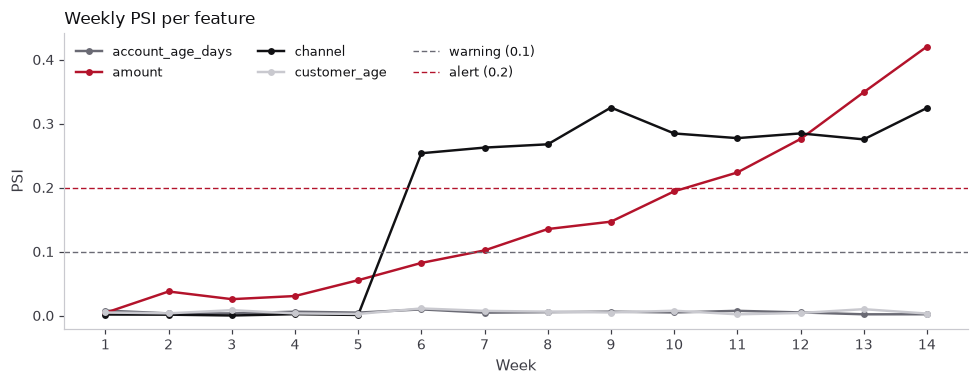

In [6]:
plots.psi_over_time(report, LANG);

In [7]:
report.pivot(index="week", columns="feature", values="status")

feature,account_age_days,amount,channel,customer_age
week,,,,
1,ok,ok,ok,ok
2,ok,ok,ok,ok
3,ok,ok,ok,ok
4,ok,ok,ok,ok
5,ok,ok,ok,ok
6,ok,ok,alert,ok
7,ok,warning,alert,ok
8,ok,warning,alert,ok
9,ok,warning,alert,ok


- `channel` jumps to alert in week 6: a sudden change shows up immediately.
- `amount` creeps up: gradual drift goes unnoticed for weeks if you only compare each batch with the previous one. That is why you always compare against the **baseline**.
- The stable features stay well below 0.1.

## 4. Kolmogorov-Smirnov: significant is not the same as important

KS compares the cumulative distributions of two samples. Its p-value depends on sample size: with 2,000 rows per batch, small changes are already “significant”. And with many tests per week, some fail by chance.

In [8]:
ks = report[report["feature"] != "channel"].pivot(index="week", columns="feature", values=["ks_stat", "ks_pvalue"])
ks.round(4)

ks_stat                             ks_pvalue                     
feature account_age_days  amount customer_age account_age_days  amount customer_age
week                                                                               
1                 0.0280  0.0244       0.0195           0.1447  0.2713       0.5462
2                 0.0152  0.0803       0.0140           0.8322  0.0000       0.8965
3                 0.0252  0.0632       0.0246           0.2378  0.0000       0.2626
4                 0.0112  0.0769       0.0160           0.9840  0.0000       0.7829
5                 0.0199  0.1001       0.0179           0.5198  0.0000       0.6551
6                 0.0385  0.1201       0.0187           0.0140  0.0000       0.6001
7                 0.0288  0.1332       0.0236           0.1243  0.0000       0.3080
8                 0.0137  0.1599       0.0195           0.9103  0.0000       0.5462
9                 0.0169  0.1691       0.0346           0.7235  0.0000       0.0364
10                0.0327  0.1805       0.0254           0.0558  0.0000       0.2299
11                0.0194  0.2012       0.0130           0.5528  0.0000       0.9533
12                0.0224  0.2193       0.0137           0.3695  0.0000       0.9103
13                0.0126  0.2483       0.0195           0.9520  0.0000       0.5462
14                0.0142  0.2681       0.0248           0.8867  0.0000       0.2541

In [9]:
amount = report[report["feature"] == "amount"].set_index("week")
print("amount: first week with KS p<0.05 :", amount.index[amount["ks_pvalue"] < 0.05].min())
print("amount: first week with PSI >= 0.1:", amount.index[amount["psi"] >= drift.PSI_WARNING].min())
stable = report[report["feature"].isin(["customer_age", "account_age_days"])]
print(f"stable features: {(stable['ks_pvalue'] < 0.05).sum()} of {len(stable)} KS tests with p<0.05 (false alarms)")

amount: first week with KS p<0.05 : 2
amount: first week with PSI >= 0.1: 7
stable features: 2 of 28 KS tests with p<0.05 (false alarms)


Use the **statistic** (PSI or the KS *D*) as the effect size for alerting, and the p-value only as support.

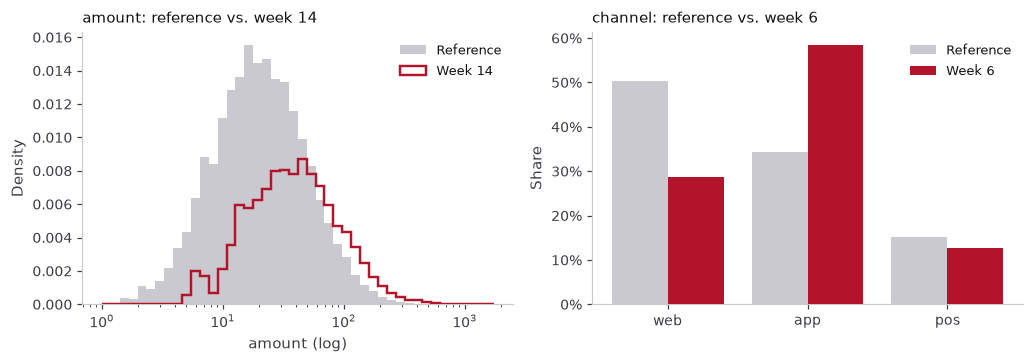

In [10]:
plots.overlays(ref, prod, amount_week=14, channel_week=6, lang=LANG);

## 5. Data-quality constraints

Drift isn't the only problem: a pipeline bug also changes the data. The completeness constraint compares missing values with the baseline.

In [11]:
report.loc[report["violations"].str.len() > 0, ["week", "feature", "psi", "missing", "violations"]]

,week,feature,psi,missing,violations
41,11,customer_age,0.002005,0.0895,[completeness: 8.9% missing (baseline 0.0%)]


The `customer_age` PSI doesn't move because it ignores missing values; only the constraint catches it. Monitor **both**.

## 6. Model quality and label delay

Whether a transaction was fraud is known weeks later (chargebacks). With `LABEL_DELAY = 3`, the AUC of week *w*'s batch is known in week *w + 3*. `flagged_rate` (the model's alert rate) is known immediately.

In [12]:
fraud_model = model.train(ref)
quality = model.weekly_quality(fraud_model, prod, LABEL_DELAY)
quality.round(3)

,week,flagged_rate,fraud_rate,auc,recall,known_at_week
0,1,0.050,0.080,0.862,0.354,4
1,2,0.056,0.074,0.846,0.320,5
2,3,0.054,0.077,0.857,0.318,6
3,4,0.058,0.075,0.861,0.373,7
4,5,0.072,0.086,0.816,0.314,8
5,6,0.053,0.072,0.875,0.371,9
6,7,0.066,0.076,0.864,0.408,10
7,8,0.069,0.074,0.837,0.429,11
8,9,0.072,0.068,0.594,0.103,12
9,10,0.086,0.060,0.614,0.167,13


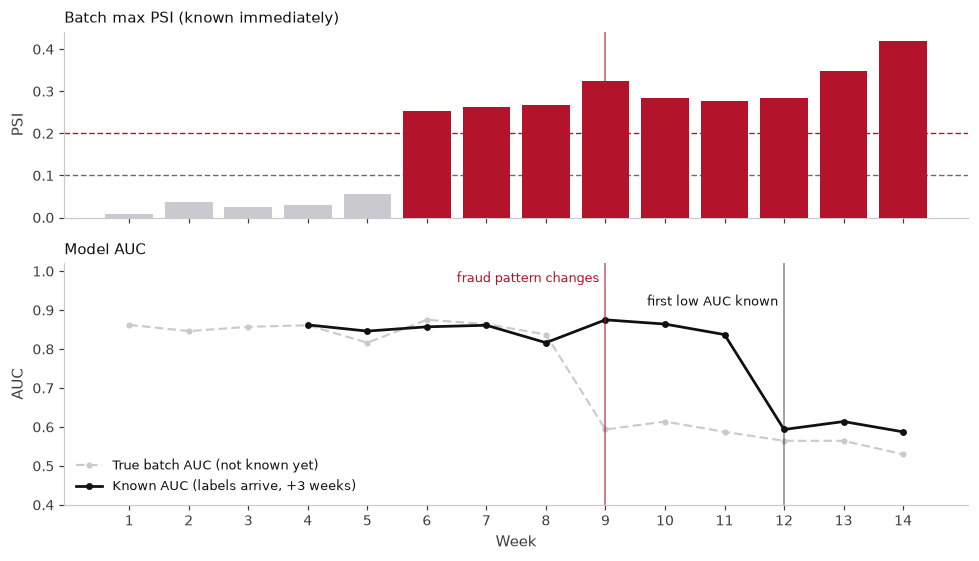

In [13]:
plots.label_delay(report, quality, gen.CONCEPT_WEEK, LABEL_DELAY, LANG);

- **Drift without degradation**: `channel` and `amount` fire alerts from week 6, but AUC holds. Drift is a signal to investigate, not proof the model is failing.
- **Degradation without drift**: in week 9 the fraud pattern changes. The inputs stay the same, so PSI and `flagged_rate` don't see it. The AUC drop only shows up in week 12, when the labels arrive.
- To shorten that gap: label a sample earlier (manual review) or watch business indicators, such as customer claims.

## 7. AWS equivalent

SageMaker Model Monitor no longer accepts new customers. Its documented replacement is the open-source SageMaker AI monitoring solutions (SageMaker AI MLflow Apps + Evidently AI), Amazon QuickSight dashboards, and Amazon CloudWatch.

| This lab | On AWS | Main differences |
|---|---|---|
| `drift.baseline` | Model Monitor baseline (`statistics.json`, `constraints.json`) or the Evidently reference dataset | On AWS, the training dataset is read as the reference from S3. |
| `drift.drift_report` (PSI, KS) | Evidently `DataDriftPreset`, run by a SageMaker Pipeline or a Lambda scheduled with EventBridge | Evidently computes PSI and KS for every feature and produces HTML reports logged to an MLflow App. |
| Completeness constraint | Evidently `DataSummaryPreset` or Model Monitor constraints | More checks: types, ranges, and outliers. |
| `model.weekly_quality` with delay | Evidently `ClassificationPreset` when ground truth arrives, joined to predictions by inference ID | On an endpoint, Data Capture stores inputs and outputs in S3. |
| `status` and thresholds | Amazon SNS alerts; CloudWatch custom metrics and anomaly detection alarms | The sample batch pipeline alerts by default when more than 30% of the features drift. |

### Try this

- Set `LABEL_DELAY` to 1 and see when the drop is detected.
- Use 5 bins with `drift.baseline(..., bins=5)` and compare the `amount` PSI.
- Lower `N_BATCH` in `generate_data.py` to 300 and watch the KS p-values change.